In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
df = pd.read_csv("sat_gpa.csv")
df

,SAT,GPA
0,1714,2.40
1,1664,2.52
2,1760,2.54
3,1685,2.74
4,1693,2.83
...,...,...
95,1934,3.54
96,1861,3.58
97,1931,3.58
98,1933,3.59


In [13]:
display(df.head())
print(df.tail())
print(type(df))

df.iloc[2]
df.info()
df.describe()


,SAT,GPA
0,1714,2.40
1,1664,2.52
2,1760,2.54
3,1685,2.74
4,1693,2.83


     SAT   GPA
95  1934  3.54
96  1861  3.58
97  1931  3.58
98  1933  3.59
99  1778  3.59
<class 'pandas.DataFrame'>
<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   SAT     100 non-null    int64  
 1   GPA     100 non-null    float64
dtypes: float64(1), int64(1)
memory usage: 1.7 KB


,SAT,GPA
count,100.000000,100.000000
mean,1850.760000,3.360500
std,101.566331,0.258845
min,1634.000000,2.400000
25%,1776.500000,3.270000
50%,1850.000000,3.410000
75%,1934.000000,3.520000
max,2050.000000,3.810000


In [18]:
print(df.sample())
print(df.sample(5))
df.shape


     SAT   GPA
19  1786  3.19
     SAT   GPA
67  1934  3.54
27  1821  3.28
87  1891  3.48
0   1714  2.40
14  1773  3.12


(100, 2)

In [19]:
df.columns

Index(['SAT', 'GPA'], dtype='str')

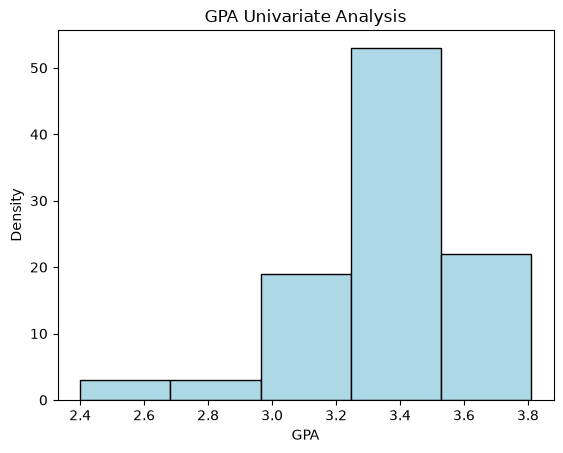

In [21]:
plt.title("GPA Univariate Analysis")
plt.xlabel("GPA")
plt.ylabel("Density")
plt.hist(df["GPA"], bins=5, edgecolor="black", color="lightblue")
plt.show()


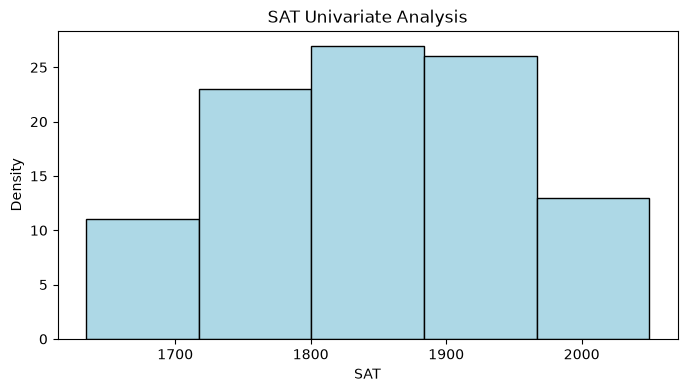

In [26]:
plt.figure(figsize=(8,4))
plt.title("SAT Univariate Analysis")
plt.xlabel("SAT")
plt.ylabel("Density")
plt.hist(df['SAT'], bins=5, edgecolor="black", color="lightblue")
plt.show()

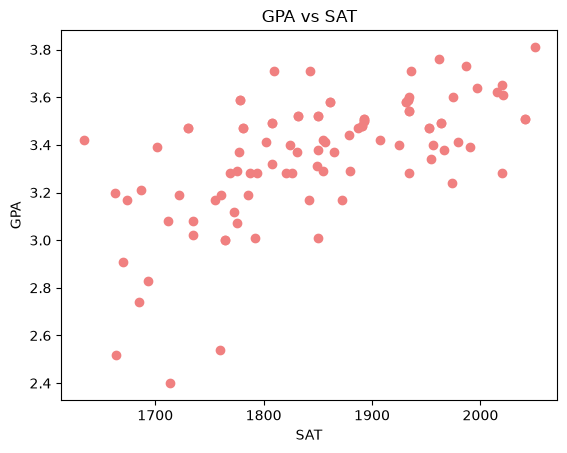

In [27]:
plt.scatter(df["SAT"], df['GPA'], color='lightcoral')
plt.title("GPA vs SAT")
plt.xlabel("SAT")
plt.ylabel("GPA")
plt.show()

In [28]:
correlation = df["SAT"].corr(df['GPA'])
print(correlation)

0.6125521257530598


In [29]:
df.isnull().sum()

SAT    0
GPA    0
dtype: int64

In [30]:
x = df.drop(columns=["GPA"])
y = df["SAT"]

In [31]:
x

,SAT
0,1714
1,1664
2,1760
3,1685
4,1693
...,...
95,1934
96,1861
97,1931
98,1933


In [32]:
y

0     1714
1     1664
2     1760
3     1685
4     1693
      ... 
95    1934
96    1861
97    1931
98    1933
99    1778
Name: SAT, Length: 100, dtype: int64

In [33]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=45)

In [34]:
x_train

,SAT
45,1925
9,1850
20,1761
18,1842
73,1934
...,...
95,1934
32,1775
3,1685
30,1769


In [35]:
x_test

,SAT
0,1714
1,1664
62,1893
76,1997
37,1954
99,1778
78,1843
38,1777
2,1760
84,1730


In [36]:
y_train

45    1925
9     1850
20    1761
18    1842
73    1934
      ... 
95    1934
32    1775
3     1685
30    1769
75    2015
Name: SAT, Length: 80, dtype: int64

In [37]:
y_test

0     1714
1     1664
62    1893
76    1997
37    1954
99    1778
78    1843
38    1777
2     1760
84    1730
60    1964
26    1787
69    1931
33    1855
51    1855
4     1693
92    1893
7     1764
10    1735
74    2021
Name: SAT, dtype: int64

In [38]:
from sklearn.linear_model import LinearRegression

In [39]:
reg = LinearRegression()

In [40]:
reg

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [41]:
reg.fit(x_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[1.]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['SAT']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-9.095e-13
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [42]:
y_pred = reg.predict(x_test)
y_pred

array([1714., 1664., 1893., 1997., 1954., 1778., 1843., 1777., 1760.,
       1730., 1964., 1787., 1931., 1855., 1855., 1693., 1893., 1764.,
       1735., 2021.])

In [43]:
pd.DataFrame({'y_test': y_test , 'y_pred':y_pred , 'MAE':(y_test-y_pred)})

,y_test,y_pred,MAE
0,1714,1714.0,2.273737e-13
1,1664,1664.0,2.273737e-13
62,1893,1893.0,0.000000e+00
76,1997,1997.0,0.000000e+00
37,1954,1954.0,0.000000e+00
99,1778,1778.0,2.273737e-13
78,1843,1843.0,0.000000e+00
38,1777,1777.0,2.273737e-13
2,1760,1760.0,2.273737e-13
84,1730,1730.0,2.273737e-13


In [44]:
from sklearn.metrics import mean_squared_error , r2_score

In [45]:
print('MSE =', mean_squared_error(y_test,y_pred) )
print("RMSE =", np.sqrt(mean_squared_error(y_test,y_pred)))
print("R2 =", r2_score(y_test,y_pred))

MSE = 2.5849394142282115e-26
RMSE = 1.6077746776921858e-13
R2 = 1.0


In [47]:
import warnings
warnings.filterwarnings("ignore",category=UserWarning)
reg.predict([[10]])

array([10.])